In [2]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [3]:
import pandas as pd
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import pandas as pd

from iblatlas.regions import BrainRegions
br = BrainRegions()
from scipy.sparse import save_npz, load_npz, csr_matrix

#task_id = int(os.environ['SLURM_ARRAY_TASK_ID'])

from bwm_functions import *


In [4]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
from bwm_functions import *

In [5]:
def get_spike_counts_in_bins(spike_times, spike_clusters, intervals):
    # Check input
    assert intervals.ndim == 2
    assert intervals.shape[1] == 2
    assert np.all(np.diff(spike_times) >= 0), "Spike times need to be sorted"
    intervals_idx = np.searchsorted(spike_times, intervals)
    # For each neuron and each interval, the number of spikes in the interval.
    cluster_ids = np.unique(spike_clusters)
    n_neurons = len(cluster_ids)
    n_intervals = intervals.shape[0]
    counts = np.zeros((n_neurons, n_intervals), dtype=np.uint32)
    for j in range(n_intervals):
        i0, i1 = intervals_idx[j, :]
        # Count the number of spikes in the window, for each neuron.
        x = np.bincount(spike_clusters[i0:i1], minlength=cluster_ids.max() + 1)
        counts[:, j] = x[cluster_ids]
    return counts, cluster_ids

In [6]:
def restrict_to_region(spikes,cluster_df,regions):
    # within_region_cluster_ids = cluster_df[cluster_df.cosmos==cosmos].cluster_id.values
    # all_cluster_ids = spikes['clusters']
   # idx = np.argwhere(cluster_df['cosmos'][spikes['clusters']].isin(cosmos))[:,0]
    idx = [i for i, x in enumerate(cluster_df['cosmos'][spikes['clusters']]) if x in regions]
    spike_times = spikes['times'][idx]
    spike_clusters= spikes['clusters'][idx]
    return spike_clusters, spike_times

In [7]:
def df_2_repsonse_matrix(df, conditions):
    response_matrix = []
    condition_matrix = []
    for pseudo_trial in range(500):
        # Sample with replacement from each condition
        sub_df = df.groupby(conditions).sample(frac=1.0, replace=True)
        # Compute mean response for each condition
        mean_df = sub_df.groupby(conditions).response.apply(lambda x: np.mean(np.stack(x), axis=0)).reset_index()
        # Append
        response_matrix.append(np.stack(mean_df.response.values))
        condition_matrix.append(mean_df[conditions].values)
    response_matrix = np.stack(response_matrix, axis=0)
    condition_matrix = np.stack(condition_matrix, axis=0)
    return response_matrix, condition_matrix

In [8]:
def get_aligned_response_matrix(spikes,clusters, trials, event,conditions, stride=.01, step=.01, n_steps=100,sigma = 5,threshold = 5,min_trials_per_condition = 10,regions=None):

    event_times = trials[event]
    n_trials = len(event_times)

    # Get spike counts in bins aligned to event times.
    intervals = []
    for trial in range(n_trials):
        start = event_times[trial] - .05
        for _ in range (n_steps):
            intervals.append([start, start + stride])
            start += step
    intervals = np.stack(intervals)
    spike_clusters,spike_times = restrict_to_region(spikes,clusters,regions)
    spike_count, cluster_id = get_spike_counts_in_bins(spike_times, spike_clusters,intervals= intervals)

    # Reshape spike_counts in 3D array
    spike_count = spike_count.T.reshape(n_trials,n_steps,-1)

    response_matrix = np.zeros(spike_count.shape)
    for neuron in range(spike_count.shape[2]):
        for trial in range(spike_count.shape[0]):
            response_matrix[trial,:,neuron] = gaussian_filter1d(spike_count[trial,:,neuron]/stride,sigma = sigma)

    rows = []
    contrasts = np.nan_to_num(-trials['contrastLeft'], copy=True, nan=1.0) * np.nan_to_num(
    trials['contrastRight'], copy=True, nan=1.0)
    for trial in range(1,n_trials):
        rows.append({'trial':trial,
                     'choice': trials['choice'][trial],
                     'prev_choice': trials['choice'][trial-1],
                     'reward': trials['feedbackType'][trial],
                     'prev_reward': trials['feedbackType'][trial-1],
                     'contrast': contrasts[trial],
                     'block': trials['probabilityLeft'][trial],
                     'side': np.sign(contrasts[trial]),
                     'prev_side': np.sign(contrasts[trial-1]),
                     'response': response_matrix[trial,:,:],})

    # Remove inactive neurons
    df = pd.DataFrame(rows)
    # Restrict to conditions that have a minimum number of trials
    df = df[df.groupby(conditions)[conditions].transform('size') >= min_trials_per_condition]
    response_matrix_train, condition_matrix_train = df_2_repsonse_matrix(df, conditions)
    return response_matrix_train, condition_matrix_train#, response_matrix_test, condition_matrix_test

In [9]:
directory_path = 'Data2'
all_items = os.listdir(directory_path)
# Filter the list to include only folders (directories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

# Hyperparameters
dim = 10
sample_size = 50
sigma = 5
n_steps = 100
threshold = .01
min_trials_per_condition = 50
conditions = ['choice']
event = "stimOn_times"
regions = ["MOp","MOs"]

In [205]:
# shape n_pseudo x n_conditions x time x n
responses = []
for i in range(len(eids)):
    eid = eids[i]
    print(i)
    full_path_to_random_folder = os.path.join(directory_path, eid)
    print(f"Randomly selected eid: {full_path_to_random_folder}")
    try:
        clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')
        clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Beryl")
        spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
        trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')
        counts_series = clusters.groupby('cosmos').size()
        print(counts_series)
        response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
            spikes, clusters, trials, event, conditions,
            stride=.005,
            step=.005,
            n_steps=n_steps,
            sigma=sigma,
            threshold=threshold,
            min_trials_per_condition=min_trials_per_condition,regions= regions)

        # Restrict to active units
        # restriction = np.logical_and(np.mean(response_matrix_train, axis=(0, 1, 2)) > 5,
        #                              np.mean(response_matrix_train, axis=(0, 1, 2)) > 5)
        # response_matrix_train = response_matrix_train[
        #     :, :, :, restriction]
        #
        # restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > 1,
        #                              np.std(response_matrix_train, axis=(0, 1, 2)) > 1)
        # response_matrix_train = response_matrix_train[
        #     :, :, :, restriction]



        n_conditions = response_matrix_train.shape[1]
        # Z-score single neuron responses
        # response_matrix_train = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
        #                                                          keepdims=True)) / np.std(response_matrix_train,
        #                                                                                   axis=(0, 1, 2),
        #                                                                                   keepdims=True)
        responses.append(response_matrix_train)
    except:
        print("Failed")
        continue

0
Randomly selected eid: Data2/b52182e7-39f6-4914-9717-136db589706e
cosmos
APN      208
CA1      388
CA3      320
DG       268
MRN       31
ProS      15
RN        13
TR        12
VISam    115
VISpm    153
root      71
void      21
dtype: int64
Failed
1
Randomly selected eid: Data2/9fc31d79-b56f-46d0-92a0-e9563caf4a7a
cosmos
DG        9
LH        8
MD       39
MH       45
PCN       4
RSPv    210
VAL       7
VM       36
root     19
dtype: int64
Failed
2
Randomly selected eid: Data2/cc45c568-c3b9-4f74-836e-c87762e898c8
cosmos
ACAd    292
ACAv    234
APN     252
CA3      67
DG        5
Eth      65
IG       52
LSr     237
MOs       3
NOT       2
PoT      70
SNr      31
SPF      17
ZI       79
root    218
dtype: int64
3
Randomly selected eid: Data2/e6de6c35-1508-4471-b7c3-f12a5c7a6d39
cosmos
CUN      93
IC       66
PB      224
PRNc    275
RM       12
root    325
dtype: int64
Failed
4
Randomly selected eid: Data2/fece187f-b47f-4870-a1d6-619afe942a7d
cosmos
CP           1
IRN        221
PAG   

In [206]:

#response_matrix_train = np.load('Movies/HB/response_matrix_train.npy')
# restriction = np.logical_and(np.mean(response_matrix_train, axis=(0, 1, 2)) > 5,
#                                      np.mean(response_matrix_train, axis=(0, 1, 2)) > 5)
# response_matrix_train = response_matrix_train[
#     :, :, :, restriction]
response_matrix_train = np.concatenate([x for x in responses if x.shape[1]==2],axis=3)
#np.save('Movies/CP/response_matrix_train.npy',response_matrix_tr
# ain)

In [207]:
response_matrix_train.shape

(500, 2, 100, 18819)

In [215]:
responses.shape

(500, 2, 100, 8026)

In [14]:
np.save('Movies/CP/response_matrix_train.npy',response_matrix_train)

FileNotFoundError: [Errno 2] No such file or directory: 'Movies/CP/response_matrix_train.npy'

In [198]:
data =np.mean(np.std(response_matrix_train, axis=0), axis=(0, 1))
#data =np.mean(np.std(responses, axis=0), axis=(0))

In [138]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DistancePreservingAE(nn.Module):
    def __init__(self, input_dim, latent_dim):
        super(DistancePreservingAE, self).__init__()

        # Encoder: Compressing data
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, latent_dim)
        )

        # Decoder: Reconstructing data
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_recon = self.decoder(z)
        return x_recon, z

def distance_loss(x, z, k=5):
    """
    Computes a loss term that penalizes distance changes between neighbors.
    """
    # 1. Compute pairwise distances in input space
    dist_x = torch.cdist(x, x, p=2)

    # 2. Find indices of k-nearest neighbors for each point
    _, knn_indices = torch.topk(dist_x, k=k+1, largest=False)

    # 3. Compute pairwise distances in latent space
    dist_z = torch.cdist(z, z, p=2)

    # 4. Sum distances in latent space for those who were neighbors in X
    # We ignore the first neighbor (index 0) because it's the point itself.
    local_loss = 0
    for i in range(1, k + 1):
        neighbor_indices = knn_indices[:, i]
        # Gather latent distances between point i and its j-th neighbor
        local_loss += torch.mean(dist_z[torch.arange(z.size(0)), neighbor_indices])

    return local_loss

# --- Hyperparameters and Training Setup ---
input_size = 200  # Example for flattened MNIST
latent_size = 2
model = DistancePreservingAE(input_size, latent_size)
optimizer = torch.optim.Adam(model.parameters(), lr=.002)
responses = np.mean(response_matrix_train, axis=0).reshape(-1,response_matrix_train.shape[3])
# Training Loop snippet
def train_step(model, data, alpha=1):
    optimizer.zero_grad()

    # Forward pass
    reconstruction, latent = model(data)

    # Loss 1: Reconstruction (Standard AE)
    recon_loss = F.mse_loss(reconstruction, data)

    # Loss 2: Distance Preservation (Isometric constraint)
    dist_pres_loss = distance_loss(data, latent)

    # Total Loss: Balanced by hyperparameter alpha
    total_loss = recon_loss + (alpha * dist_pres_loss)

    total_loss.backward()
    optimizer.step()

    return total_loss.item()



In [143]:
training_data = torch.tensor(responses.T).float()
for i in range(4000):
    loss = train_step(model, training_data, alpha=0.)
    print(loss)

0.3366932272911072
0.3373092710971832
0.3390808701515198
0.3381728231906891
0.338605672121048
0.3377061188220978
0.33832111954689026
0.3382720351219177
0.34032291173934937
0.3368273377418518
0.3356427252292633
0.33521321415901184
0.3354889154434204
0.33652713894844055
0.33685770630836487
0.33736908435821533
0.3356500267982483
0.3348853886127472
0.33473652601242065
0.3351133167743683
0.3360688388347626
0.3362421691417694
0.3370341956615448
0.3355531096458435
0.334883451461792
0.3346904218196869
0.33550944924354553
0.3377342224121094
0.34535396099090576
0.34150296449661255
0.34674057364463806
0.3413311839103699
0.3361094892024994
0.3385668992996216
0.34349727630615234
0.33594104647636414
0.3518197536468506
0.35128453373908997
0.35721468925476074
0.3389087915420532
0.35868552327156067
0.3393307626247406
0.35149455070495605
0.340742290019989
0.3437444567680359
0.3418405055999756
0.33940598368644714
0.344338595867157
0.33769166469573975
0.3408746123313904
0.3392042815685272
0.33737036585807

KeyboardInterrupt: 

In [262]:
responses = response_matrix_train
restriction =np.mean(responses, axis=(0, 1, 2)) > 5
responses = responses[
    :, :, :, restriction]

restriction = np.std(responses, axis=(0, 1, 2)) > 1
responses = responses[
    :, :, :, restriction]

restriction = np.std(responses, axis=(0, 1, 2)) <4
responses = responses[
    :, :, :, restriction]



responses = (responses - np.mean(responses, axis=(0, 1, 2),
                                                         keepdims=True)) / np.std(responses,
                                                                                  axis=(0, 1, 2),
                                                                                  keepdims=True)
data =np.mean(np.std(responses, axis=0), axis=(0, 1))

responses = np.mean(responses, axis=0).reshape(-1,responses.shape[3])


In [263]:
responses.shape,data.shape

((200, 5191), (5191,))

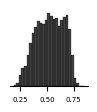

In [264]:
# var = np.var(response_matrix_train,axis = 0)
# mu = np.mean(response_matrix_train,axis = (0,1,2))
#data =np.mean(np.std(response_matrix_train, axis=0), axis=(0, 1))


fig = plt.figure(figsize=(1,1))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.histplot(x = data,color='k',stat = 'probability')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=5, bottom=True)
ax.yaxis.set_tick_params(labelsize=5, left=True)
#ax.set_ylim(0,.2)
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)
ax.spines['left'].set_visible(False)
# ax.spines['bottom'].set_visible(False)
# ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_gain_dist.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

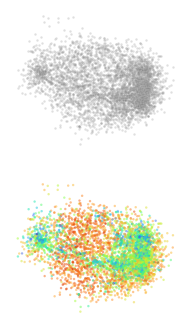

In [271]:
#from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE
import umap
from umap.parametric_umap import ParametricUMAP

fig = plt.figure(figsize=(3,4))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])

#pca = TSNE(n_components =2,perplexity = 500)
embedder = umap.UMAP(densmap=True,dens_lambda=8 ).fit(responses.T)
#embedder = ParametricUMAP(dens_lambda = 10,parametric_reconstruction= True)
x_proj = embedder.transform(responses.T)
#x_proj = TSNE(n_components = 2,perplexity = 1000).fit_transform(responses.T)
# embedder.fit(responses.T)
# x_proj= embedder.transform(responses.T)
#x_proj = model.encoder(training_data).detach().numpy()
#x_proj = pca.fit_transform(responses.T)
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s = 3,ax=ax0,legend = False,alpha = .25,color='gray')
#sns.kdeplot(x=x_proj[:,0], y=x_proj[:,1],ax=ax0,legend = False,color='gray',fill=True,levels = 30,alpha = .5)
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=3,ax=ax1,legend = False,lw = 0,alpha = .5,hue = data,palette = 'turbo')

for ax in [ax0,ax1]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [176]:
inv_transformed_points = embedder.inverse_transform(x_proj)

In [178]:
inv_transformed_points.shape

(8025, 200)

In [179]:
from sklearn.metrics import r2_score
scores = []
for neuron in range(responses.shape[1]):
    scores.append(r2_score(responses[:,neuron], inv_transformed_points[neuron,:]))

<Axes: ylabel='Count'>

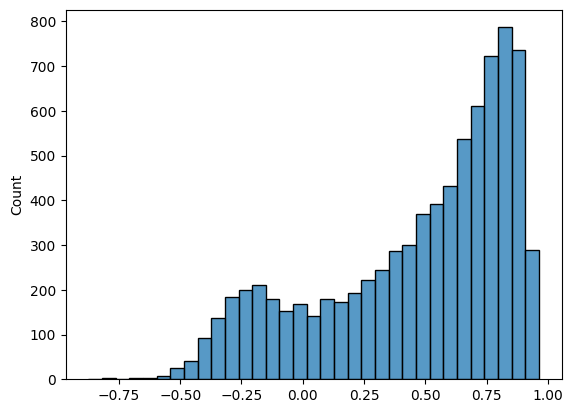

In [181]:
plt.figure()
sns.histplot(x = scores)

<Axes: >

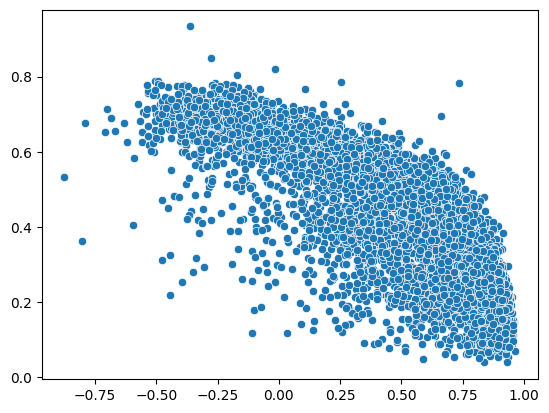

In [183]:
plt.figure()
sns.scatterplot(x = scores, y = data)

In [185]:
recon_loss = []
for n_components in range(2,5):
    embedder = umap.UMAP(n_components = n_components ).fit(responses.T)
    x_proj = embedder.transform(responses.T)
    inv_transformed_points = embedder.inverse_transform(x_proj)
    scores = []
    for neuron in range(responses.shape[1]):
        scores.append(r2_score(responses[:,neuron], inv_transformed_points[neuron,:]))
    recon_loss.append(np.mean(np.array(scores)))

#embedder = ParametricUMAP(dens_lambda = 10,parametric_reconstruction= True)



In [187]:
embedder = umap.UMAP(n_components = 1 ).fit(responses.T)
x_proj = embedder.transform(responses.T)
inv_transformed_points = embedder.inverse_transform(x_proj)

ValueError: Need at least 2-D data

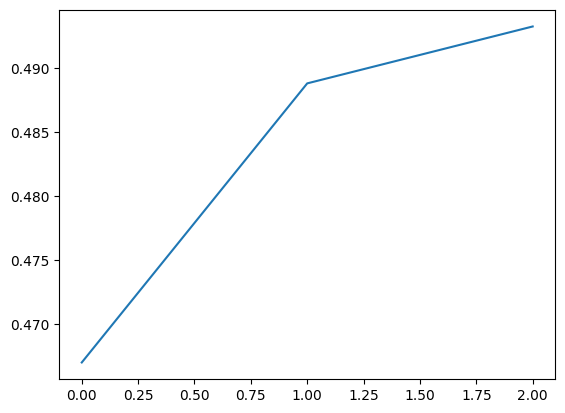

In [186]:
plt.figure()
plt.plot(recon_loss)

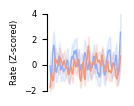

In [204]:
neuron = np.argsort(data)[-5]
rows = []
for condition in range(response_matrix_train.shape[1]):
    for trial in range(response_matrix_train.shape[0]):
        for t in range(response_matrix_train.shape[2]):
            rows.append({'condition': condition,
                         'trial': trial,
                         't':t,
                         'x': response_matrix_train[trial, condition, t, neuron].item(),})
df = pd.DataFrame(rows)
fig = plt.figure(figsize=(1,1))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.lineplot(data = df[df.condition ==0], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[0])
sns.lineplot(data = df[df.condition ==1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[2])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(True)
ax.set_ylim(-2,4)
ax.set_ylabel("Rate (Z-scored)",size = 6)
ax.set_xlabel("Time from stim",size = 6)
plt.savefig('Figures/Figure_1_2.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [160]:
neuron_response = response_matrix_train[:,:,:,0]

In [162]:
neuron_response = np.mean(neuron_response, axis = 2)

In [163]:
neuron_response.shape

(500, 2)

In [109]:
inv_transformed_points = embedder.inverse_transform(x_proj)

ValueError: Inverse transform not available for densMAP.

In [119]:
import numpy as np

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px


fig = make_subplots(
     rows=1, cols=1,
     specs=[[{"type": "scene"}]])


fig.add_trace(go.Scatter3d(x=x_proj[:,0],
                          y=x_proj[:,1],
                          z=x_proj[:,2],
                              mode='markers',

                        marker=dict(
                            color=data,
                            colorscale='turbo',
                            opacity=.5,
                            size = 3
                        )), row=1, col=1)
#px.colors.diverging.balance
#
fig.update_layout( scene = dict(xaxis = dict(showgrid = False,showticklabels = False),
                                   yaxis = dict(showgrid = False,showticklabels = False),
                                   zaxis = dict(showgrid = False,showticklabels = False),

             ))
fig.update_scenes(xaxis_visible=False, yaxis_visible=False,zaxis_visible=False )

IndexError: index 2 is out of bounds for axis 1 with size 2

In [28]:
import umap
import umap.plot

/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/umap/plot.py:20: UserWarning: The umap.plot package requires extra plotting libraries to be installed.
    You can install these via pip using

    pip install umap-learn[plot]

    or via conda using

     conda install pandas matplotlib datashader bokeh holoviews colorcet scikit-image
    
  warn(


ImportError: umap.plot requires pandas matplotlib datashader bokeh holoviews scikit-image and colorcet to be installed

<Figure size 640x480 with 0 Axes>

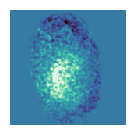

In [191]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation
from scipy.ndimage import (gaussian_filter)
from sklearn.manifold import Isomap
from sklearn.manifold import TSNE

mean_responses = np.mean(response_matrix_train, axis=0)
#mean_responses = mean_responses * (data>.5).astype(int)
#pca = TSNE(n_components = 2)
#
#x_proj = pca.fit_transform(responses.T,perplexity=1000)

embedding =(10*x_proj[:,:2]).astype(int) - (10*x_proj[:,:2]).astype(int).min()
def spatial_embedding(response,embedding,sigma):
    m = np.zeros((embedding.max()+1,embedding.max()+1))
    for neuron in range(embedding.shape[0]):
        m[embedding[neuron,1],embedding[neuron,0]] = response[neuron]
    m = np.flipud(m)
    return gaussian_filter(m,sigma)

t = 70
sigma = 1
vmin = -1
vmax = 1
trial = 1
m = spatial_embedding(mean_responses[0,t,:],embedding,sigma)
plt.figure()
from scipy.ndimage import gaussian_filter
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
# sns.diverging_palette(145, 300, s=60, as_cmap=True)
sns.heatmap(m ,vmin = vmin,vmax = vmax,cbar = False,ax=ax,cmap ="mako", center=0)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_'+str(t)+'.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [167]:
(data>.6).astype(int)

array([1, 0, 0, ..., 1, 0, 0])

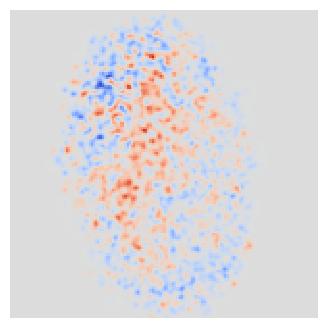

In [192]:
num_frames = mean_responses.shape[1]
trial = 0

data_list = [spatial_embedding(mean_responses[trial,i,:] - mean_responses[trial+1,i,:] ,embedding,sigma)  for i in range(num_frames)]

# 2. Set up the figure and axes
fig, ax = plt.subplots(figsize=(4,4))

# Set consistent colorbar range (vmin/vmax) if desired, for smooth animation

def update(frame_num):
    """Updates the heatmap for each frame of the animation."""
    ax.clear()  # Clear the previous frame's axis
    current_data = data_list[frame_num]
    sns.heatmap(current_data, ax=ax, cbar=False, vmin=vmin, vmax=vmax,center=0,cmap = 'coolwarm')
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
anim = FuncAnimation(fig, update, frames=num_frames, interval=200, blit=False)
try:
    os.makedirs("Movies/" + eid)
except:
    pass
anim.save('Movies/' + "CP" +'/' +'side'+str(sigma)+'_'+"highvariability" + ".mp4", writer='ffmpeg', fps=5)

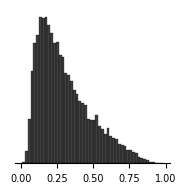

In [15]:


fig = plt.figure(figsize=(2, 2))
from scipy.spatial import ConvexHull

gs = gridspec.GridSpec(1, 1)
ax = fig.add_subplot(gs[0, 0])
sns.histplot(x = data,ax=ax,color='black',stat = 'probability')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel('')
#ax.set_xlim(.2,1)

ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',

            dpi=450,
            bbox_inches='tight', transparent=True)


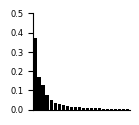

In [23]:
# Dimensionality




pca = PCA().fit(mean_responses.reshape(-1,mean_responses.shape[2]))
fig = plt.figure(figsize=(1.25, 1.25))
from scipy.spatial import ConvexHull

gs = gridspec.GridSpec(1, 1)

ax = fig.add_subplot(gs[0, 0])
sns.barplot(x = np.arange(1,25),y = pca.explained_variance_ratio_[:24],color='black')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)

ax.set_ylim(0,.5)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',

            dpi=450,
            bbox_inches='tight', transparent=True)


In [25]:
np.save('dimensionality.npy',pca.explained_variance_ratio_[:500])

In [26]:
pwd

'/Users/cl1704/PycharmProjects/embedding_dimension/BWM'

In [20]:
np.save('Movies/CP/response_matrix_train.npy',response_matrix_train,)

In [35]:

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots



fig = make_subplots(
     rows=1, cols=1,
     specs=[[{"type": "scene"}]])


# Sample data
z = x_proj[:,0]

y = x_proj[:,1]
x = x_proj[:,2]

# Create figure and 3D axes
#
#ax = fig.add_subplot(111, projection='3d')
fig.add_trace(go.Scatter3d(x=x,
                          y=y,
                          z=z,
                              mode='markers',

                        marker=dict(
                            color=data,
                            colorscale='turbo',
                            opacity=1,
                            size = 1
                        )), row=1, col=1)
# fig.add_trace(go.Scatter3d(x=x, y=y, z=z2,mode='markers',opacity = .5,marker=dict(size=1,color='gray')),)
# # Create the scatter plot
# fig.add_trace(go.Surface(x=X, y=Y, z=Z,
#                          colorscale= [[0, "rgb(254, 254, 254)"],
#                                       [1, "rgb(254, 254, 254)"]],
#                          showscale=False,
#                          opacity =0.65), row=1, col=1)
fig.update_layout( scene = dict(xaxis = dict(showgrid = False,showticklabels = False),
                                   yaxis = dict(showgrid = False,showticklabels = False),
                                   zaxis = dict(showgrid = False,showticklabels = False),

             ))
fig.update_scenes(xaxis_visible=False, yaxis_visible=False,zaxis_visible=False )


IndexError: index 2 is out of bounds for axis 1 with size 2

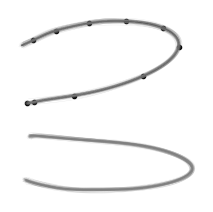

In [48]:
##########################################################
################## Neural Manifold #######################
##########################################################

fig = plt.figure(figsize=(2.5,2.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
mean_responses = np.mean(response_matrix_train,axis=0)
pca = PCA().fit(mean_responses.reshape(-1,mean_responses.shape[2]))
# for c in range(response_matrix_train.shape[1]):
#     x_proj = pca.transform(np.mean(response_matrix_train[:,c,:,:],axis=0))
#     ax.plot(x_proj[:,2], x_proj[:,1],lw = 1,color ='gray',alpha = 1)
x_proj = pca.transform(np.mean(response_matrix_train[:,0,:,:],axis=0))
ax.plot(x_proj[:,2], x_proj[:,1],lw = 1,color ='k',alpha = 1,marker = '.',markevery = 10)
for c in range(response_matrix_train.shape[1]):
    for k in range(100):
        x_proj = pca.transform(response_matrix_train[k,c,:,:])
        ax.plot(x_proj[:,2], x_proj[:,1],lw = .25,color ='gray',alpha = .2)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

